# Assignment 2: Diabetes Classification
**Group members:** Borgar, Robert, Oskar

## Understanding and evaluating a classification workflow
We investigate survey features associated with the supplied diabetes outcome and fit Logistic Regression. Our aim is to understand the data, keep TEST protected, and interpret predictions and errors rather than chase a high accuracy score.

**Running in JupyterHub:** upload this notebook and `diabetes_binary_classification_data.csv` into the same folder. Select a Python 3 kernel and use **Restart Kernel and Run All Cells**. The notebook uses pandas, NumPy, matplotlib and scikit-learn, as in Assignment 1. Outputs below were generated from the supplied CSV.


**Sources:** the supplied *Assignment 2: Diabetes Classification* handout and *Diabetes Classification: Understanding the Dataset* guide. Feature meanings and coding follow the guide. The separate written submission and group reflection are not included here.

## 1. Load the data and check its structure
**Question:** What does one row represent, and which column are we trying to predict?

Each row represents one survey respondent. `Diabetes_binary` is the target: **0 = no diabetes; 1 = prediabetes or diabetes**, following the supplied guide. We cannot distinguish prediabetes from diabetes with this binary target. The remaining 21 columns are candidate predictors.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score)

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
pd.set_option('display.max_columns', 25)
RANDOM_STATE = 42
DATA_PATH = Path('diabetes_binary_classification_data.csv')
if not DATA_PATH.is_file():
    raise FileNotFoundError('Upload diabetes_binary_classification_data.csv into the notebook folder.')
df = pd.read_csv(DATA_PATH)
print('Python:', sys.version.split()[0])
print('pandas:', pd.__version__, '| NumPy:', np.__version__, '| scikit-learn:', sklearn.__version__)
print('Shape:', df.shape)
df.info()
display(df.head())

Python: 3.12.14
pandas: 2.2.3 | NumPy: 2.3.5 | scikit-learn: 1.8.0
Shape: (253680, 22)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost      

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


Missing values: 0
Repeated rows after the first occurrence: 24206
All supplied feature codes are within the documented ranges.


,Count,Proportion (%)
Diabetes_binary,,
0.0,218334,86.07
1.0,35346,13.93


[Text(0.5, 0, 'Target class (0 = no diabetes; 1 = prediabetes or diabetes)'), Text(0, 0.5, 'Respondents'), Text(0.5, 1.0, 'Full dataset: target class balance')]

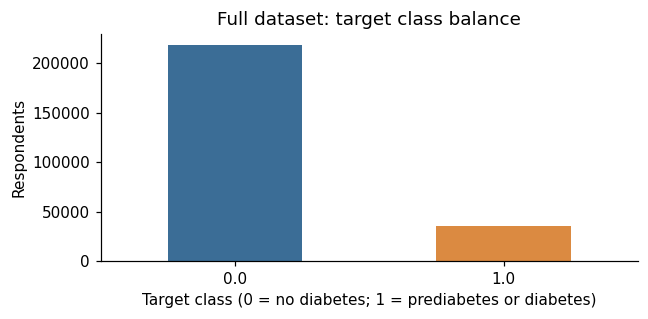

In [2]:
target = 'Diabetes_binary'
numerical_features = ['BMI', 'MentHlth', 'PhysHlth']
ordinal_features = ['GenHlth', 'Age', 'Education', 'Income']
binary_features = ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke',
                   'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
                   'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
feature_columns = numerical_features + binary_features + ordinal_features
assert len(feature_columns) == len(set(feature_columns)) == 21
assert set(df.columns) == set(feature_columns + [target])
assert set(df[target].unique()) == {0, 1}
assert not df.isna().any().any(), 'Unexpected missing values: investigate before fitting.'
for col in binary_features:
    assert df[col].isin([0, 1]).all(), f'Unexpected category in {col}'
for col, upper in {'GenHlth': 5, 'Age': 13, 'Education': 6, 'Income': 8}.items():
    assert df[col].isin(range(1, upper + 1)).all(), f'Unexpected category in {col}'
assert df['BMI'].between(12, 98).all()
assert df[['MentHlth', 'PhysHlth']].isin(range(31)).all().all()
print('Missing values:', df.isna().sum().sum())
print('Repeated rows after the first occurrence:', df.duplicated().sum())
print('All supplied feature codes are within the documented ranges.')

class_summary = df[target].value_counts().sort_index().rename('Count').to_frame()
class_summary['Proportion (%)'] = class_summary['Count'] / len(df) * 100
display(class_summary.round(2))
ax = class_summary['Count'].plot.bar(color=['#3B6D96', '#DB8A41'], rot=0, figsize=(6, 3))
ax.set(xlabel='Target class (0 = no diabetes; 1 = prediabetes or diabetes)',
       ylabel='Respondents', title='Full dataset: target class balance')
plt.tight_layout()
plt.show()

**Observation and decision (Q1):** There are 218,334 class-0 respondents and 35,346 class-1 respondents: approximately 86.1% and 13.9%. The target is imbalanced. Predicting class 0 for everyone would already give about 86.1% accuracy while finding none of class 1. We therefore report precision, recall, F1 and the confusion matrix alongside accuracy.

We keep all **24,206 repeated rows**, as required by the guide. Identical survey answers do not establish that the same person was recorded twice. There are no missing values, so imputation is unnecessary. We do not remove unusual BMI values merely because they are extreme.

## 2. Understand feature meanings before choosing methods
**Question (Q2):** Why is the stored number not enough to identify a feature's type?

| Example | Meaning | Type | Implication |
|---|---|---|---|
| BMI = 30 | A measured body mass index | Numerical measurement | Compare distributions and scale for Logistic Regression |
| HighBP = 1 | Respondent has high blood pressure | Binary categorical | Compare categories; retain its 0/1 encoding |
| Age = 9 | Age group 60–64, not nine years old | Ordered categorical | Preserve order and label the groups; do not interpret code differences as years |

`MentHlth` and `PhysHlth` are numerical counts of days, even though they contain integers. `GenHlth`, `Age`, `Education` and `Income` are ordered category codes. `Sex` uses 0 = female and 1 = male; it is not a yes/no health indicator. All features are stored numerically, so selecting preprocessing from pandas dtypes alone would miss these distinctions.

In [3]:
ordinal_labels = {
    'GenHlth': ['Excellent', 'Very good', 'Good', 'Fair', 'Poor'],
    'Age': ['18–24', '25–29', '30–34', '35–39', '40–44', '45–49', '50–54',
            '55–59', '60–64', '65–69', '70–74', '75–79', '80+'],
    'Education': ['No school / kindergarten', 'Grades 1–8', 'Grades 9–11',
                  'High school graduate', 'Some college / technical', 'College / technical graduate'],
    'Income': ['<$10k', '$10k–<15k', '$15k–<20k', '$20k–<25k', '$25k–<35k',
               '$35k–<50k', '$50k–<75k', '$75k+']
}
feature_types = pd.DataFrame({
    'Feature': feature_columns,
    'Type': (['Numerical'] * len(numerical_features)
             + ['Binary categorical'] * len(binary_features)
             + ['Ordered categorical'] * len(ordinal_features))
})
display(feature_types)

,Feature,Type
0,BMI,Numerical
1,MentHlth,Numerical
2,PhysHlth,Numerical
3,HighBP,Binary categorical
4,HighChol,Binary categorical
5,CholCheck,Binary categorical
6,Smoker,Binary categorical
7,Stroke,Binary categorical
8,HeartDiseaseorAttack,Binary categorical
9,PhysActivity,Binary categorical


## 3. Reserve TRAIN and TEST before detailed exploration
**Question (Q4):** How do we prevent evaluation information from influencing the fitted model?

We use an 80/20 split with `stratify=y` and a fixed random seed. The handout lists EDA before splitting; here we reserve TEST earlier, as in Assignment 1, and perform all detailed feature EDA on TRAIN. This still covers every input feature and gives stronger protection against choosing a workflow from TEST patterns. The full-data checks above establish schema and class balance only.

Preprocessing statistics and model parameters will be learned from TRAIN only. We check split sizes and class proportions, then leave TEST features untouched until final prediction. We do not resample either split.

In [4]:
X = df.drop(columns=target)
y = df[target].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
train_df = X_train.copy()
train_df[target] = y_train
split_summary = pd.DataFrame({
    'Rows': [len(y_train), len(y_test)],
    'Class 0': [(y_train == 0).sum(), (y_test == 0).sum()],
    'Class 1': [(y_train == 1).sum(), (y_test == 1).sum()],
    'Class 1 (%)': [100 * y_train.mean(), 100 * y_test.mean()]
}, index=['TRAIN', 'TEST'])
display(split_summary.round(3))
assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(df)

,Rows,Class 0,Class 1,Class 1 (%)
TRAIN,202944,174667,28277,13.933
TEST,50736,43667,7069,13.933


## 4. Numerical EDA: distributions and differences between classes
**Question:** Do BMI and days of poor physical or mental health differ between the two target classes?

We examine all three numerical features. Separate class-normalized histograms prevent the larger class from dominating the comparison. Boxplots show medians and spread; outliers are hidden only in the boxplots for readability, retained in the data and included in the histograms and tables.

BMI                                 MentHlth               \
                  count   mean median   std   min   max    count  mean median   
Diabetes_binary                                                                 
0                174667  27.80   27.0  6.27  12.0  98.0   174667  2.98    0.0   
1                 28277  31.97   31.0  7.37  13.0  98.0    28277  4.48    0.0   

                                 PhysHlth                                 
                  std  min   max    count  mean median    std  min   max  
Diabetes_binary                                                           
0                7.11  0.0  30.0   174667  3.65    0.0   8.07  0.0  30.0  
1                8.96  0.0  30.0    28277  7.98    1.0  11.30  0.0  30.0

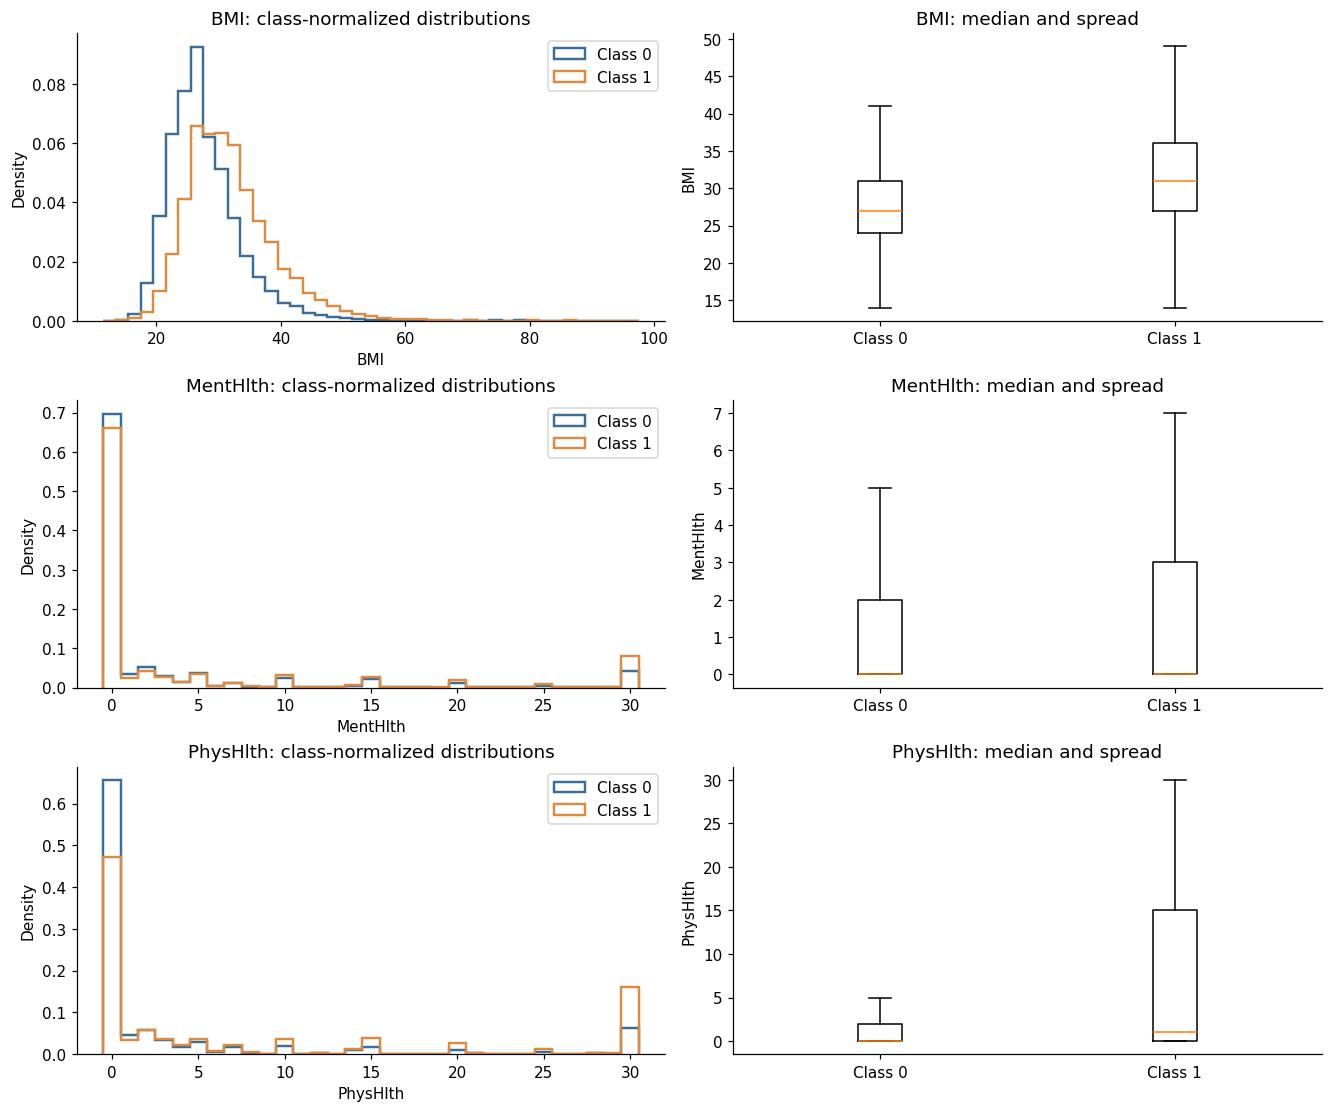

In [5]:
numeric_summary = train_df.groupby(target)[numerical_features].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)
display(numeric_summary.round(2))
fig, axes = plt.subplots(3, 2, figsize=(12, 10), constrained_layout=True)
for row, col in enumerate(numerical_features):
    bins = np.arange(11.5, 99.5, 2) if col == 'BMI' else np.arange(-0.5, 31.5, 1)
    groups = [train_df.loc[train_df[target] == k, col] for k in [0, 1]]
    for k, values, color in zip([0, 1], groups, ['#3B6D96', '#DB8A41']):
        axes[row, 0].hist(values, bins=bins, density=True, histtype='step',
                          linewidth=1.6, color=color, label=f'Class {k}')
    axes[row, 0].set(title=f'{col}: class-normalized distributions', xlabel=col, ylabel='Density')
    axes[row, 0].legend()
    axes[row, 1].boxplot(groups, showfliers=False)
    axes[row, 1].set_xticks([1, 2], ['Class 0', 'Class 1'])
    axes[row, 1].set(title=f'{col}: median and spread', ylabel=col)
plt.show()

## 5. Binary categorical EDA: counts and class-1 proportions
**Question:** How common is each category, and does the class-1 proportion differ between categories?

For every binary feature we show category counts and the percentage of respondents in that category who have target 1. These are **within-category percentages**, not each category's share of all class-1 respondents. Category counts help us judge how much data supports each percentage. A dashed line marks the overall TRAIN class-1 percentage.

Respondents  Class 1 count  Share of TRAIN (%)  \
Feature              Code                                                   
HighBP               0.0        115882           6984               57.10   
                     1.0         87062          21293               42.90   
HighChol             0.0        116834           9307               57.57   
                     1.0         86110          18970               42.43   
CholCheck            0.0          7627            189                3.76   
                     1.0        195317          28088               96.24   
Smoker               0.0        113068          13612               55.71   
                     1.0         89876          14665               44.29   
Stroke               0.0        194744          25663               95.96   
                     1.0          8200           2614                4.04   
HeartDiseaseorAttack 0.0        183817          21957               90.58   
                     1.0         19127           6320                9.42   
PhysActivity         0.0         49317          10426               24.30   
                     1.0        153627          17851               75.70   
Fruits               0.0         74191          11808               36.56   
                     1.0        128753          16469               63.44   
Veggies              0.0         38270           6847               18.86   
                     1.0        164674          21430               81.14   
HvyAlcoholConsump    0.0        191634          27620               94.43   
                     1.0         11310            657                5.57   
AnyHealthcare        0.0          9914           1140                4.89   
                     1.0        193030          27137               95.11   
NoDocbcCost          0.0        185770          25251               91.54   
                     1.0         17174           3026                8.46   
DiffWalk             0.0        168817          17744               83.18   
                     1.0         34127          10533               16.82   
Sex                  0.0        113443          14726               55.90   
                     1.0         89501          13551               44.10   

                           Class 1 (%)  
Feature              Code               
HighBP               0.0          6.03  
                     1.0         24.46  
HighChol             0.0          7.97  
                     1.0         22.03  
CholCheck            0.0          2.48  
                     1.0         14.38  
Smoker               0.0         12.04  
                     1.0         16.32  
Stroke               0.0         13.18  
                     1.0         31.88  
HeartDiseaseorAttack 0.0         11.95  
                     1.0         33.04  
PhysActivity         0.0         21.14  
                     1.0         11.62  
Fruits               0.0         15.92  
                     1.0         12.79  
Veggies              0.0         17.89  
                     1.0         13.01  
HvyAlcoholConsump    0.0         14.41  
                     1.0          5.81  
AnyHealthcare        0.0         11.50  
                     1.0         14.06  
NoDocbcCost          0.0         13.59  
                     1.0         17.62  
DiffWalk             0.0         10.51  
                     1.0         30.86  
Sex                  0.0         12.98  
                     1.0         15.14

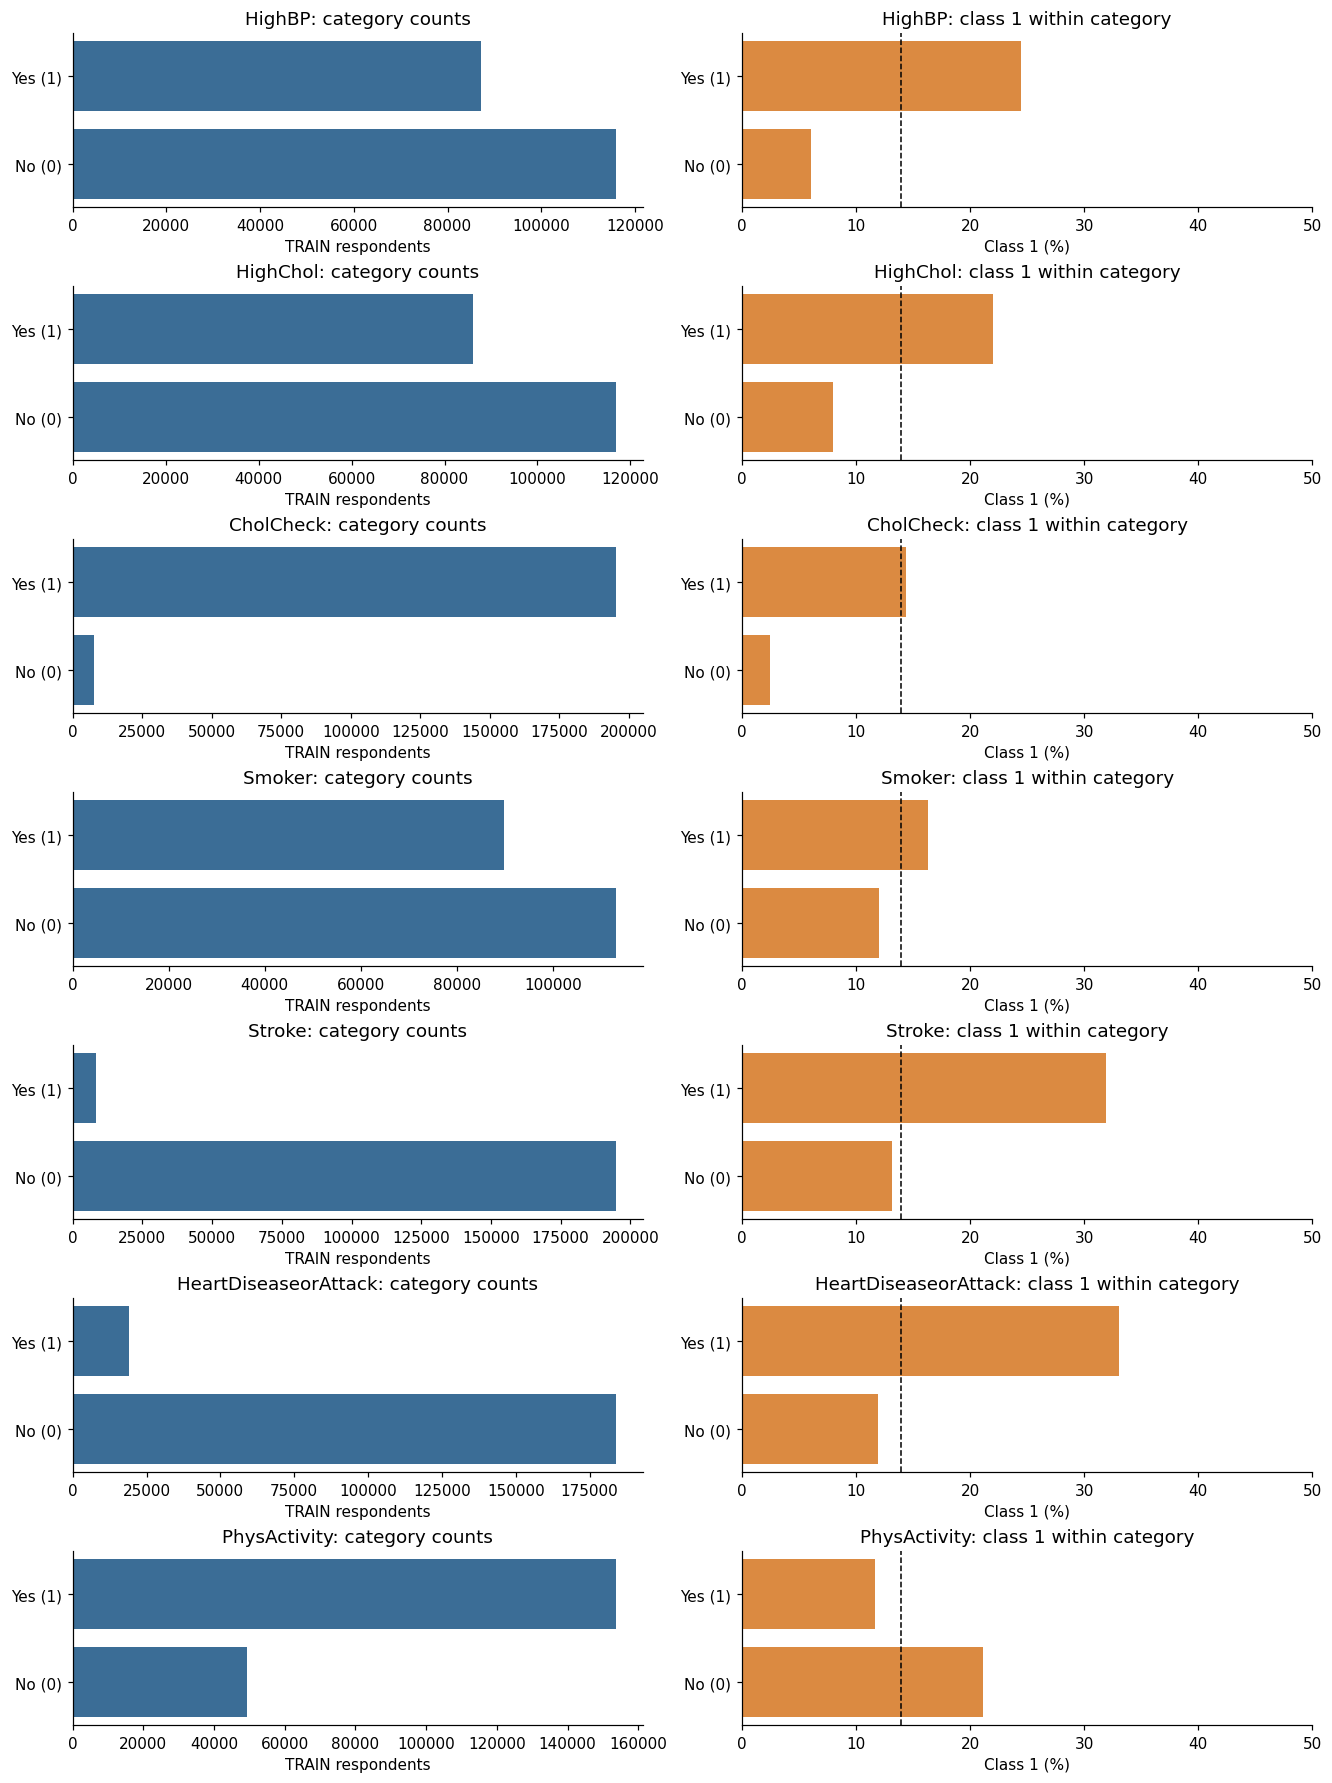

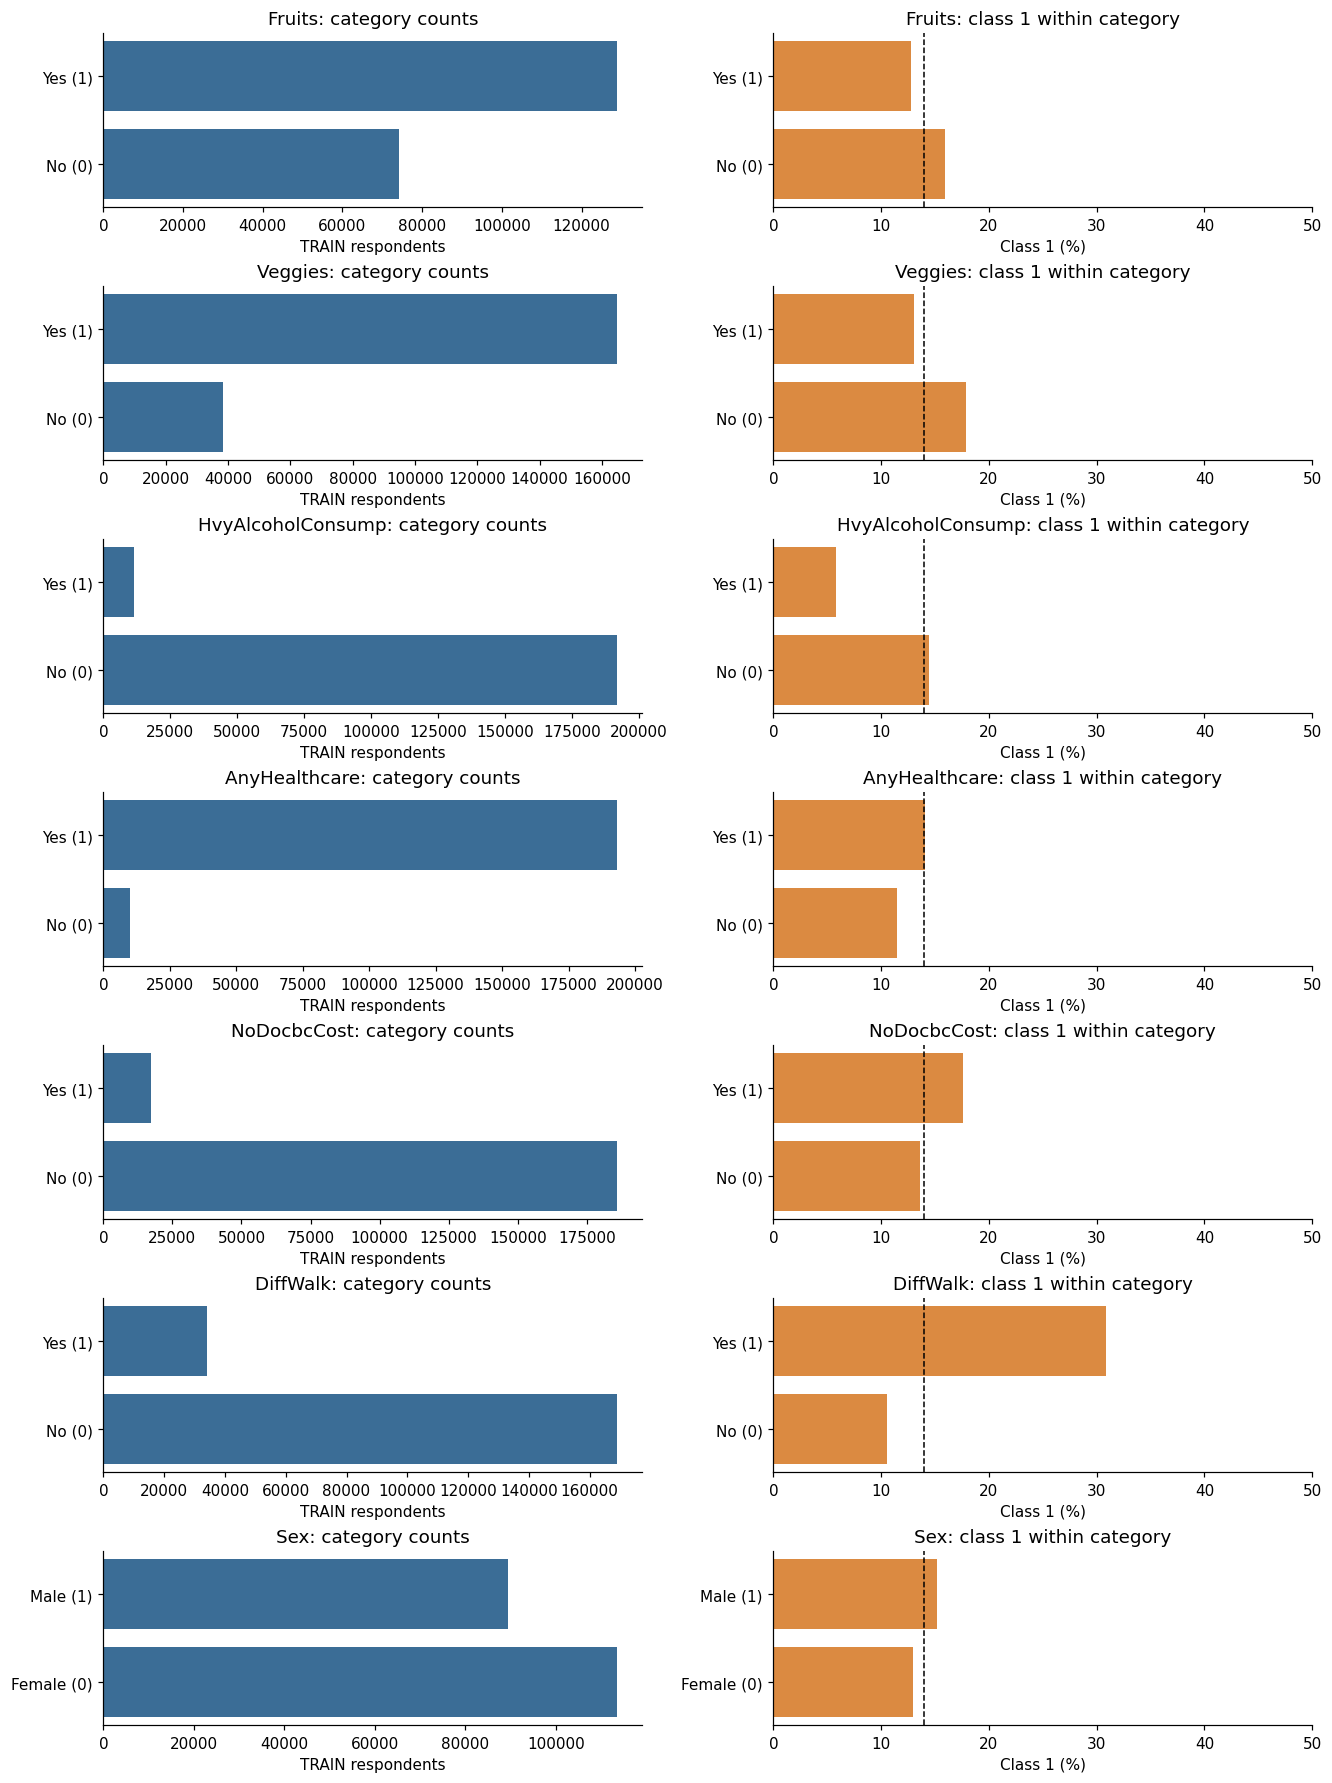

In [6]:
def category_summary(data, feature):
    summary = data.groupby(feature)[target].agg(['size', 'sum', 'mean'])
    summary.columns = ['Respondents', 'Class 1 count', 'Class 1 proportion']
    summary['Share of TRAIN (%)'] = 100 * summary['Respondents'] / len(data)
    summary['Class 1 (%)'] = 100 * summary['Class 1 proportion']
    return summary.drop(columns='Class 1 proportion')

binary_tables = {col: category_summary(train_df, col) for col in binary_features}
display(pd.concat(binary_tables, names=['Feature', 'Code']).round(2))

# Two figures keep all 14 features legible without one excessively tall plot.
for start in range(0, len(binary_features), 7):
    selected = binary_features[start:start + 7]
    fig, axes = plt.subplots(len(selected), 2, figsize=(12, 2.3 * len(selected)),
                             constrained_layout=True)
    for row, col in enumerate(selected):
        summary = binary_tables[col].reindex([0, 1])
        labels = ['Female (0)', 'Male (1)'] if col == 'Sex' else ['No (0)', 'Yes (1)']
        axes[row, 0].barh(labels, summary['Respondents'], color='#3B6D96')
        axes[row, 0].set(title=f'{col}: category counts', xlabel='TRAIN respondents')
        axes[row, 1].barh(labels, summary['Class 1 (%)'], color='#DB8A41')
        axes[row, 1].axvline(100 * y_train.mean(), color='black', linestyle='--', linewidth=1)
        axes[row, 1].set(title=f'{col}: class 1 within category', xlabel='Class 1 (%)', xlim=(0, 50))
    plt.show()

## 6. Ordered categorical EDA: preserve category order
**Question:** How does the class-1 proportion change across general health, age, education and income groups?

We keep the documented order rather than sorting categories by the observed diabetes proportion. Counts and percentages are shown together. Category-code correlation is not used: income code 8 is not eight dollars, and adjacent categories do not necessarily represent equal measured distances.

GenHlth
Age
Education
Income
EDA coverage: all 21 input features explored.


,Respondents,Class 1 count,Share of TRAIN (%),Class 1 (%)
Excellent,36262,912,17.87,2.52
Very good,71133,5074,35.05,7.13
Good,60582,10790,29.85,17.81
Fair,25347,7840,12.49,30.93
Poor,9620,3661,4.74,38.06


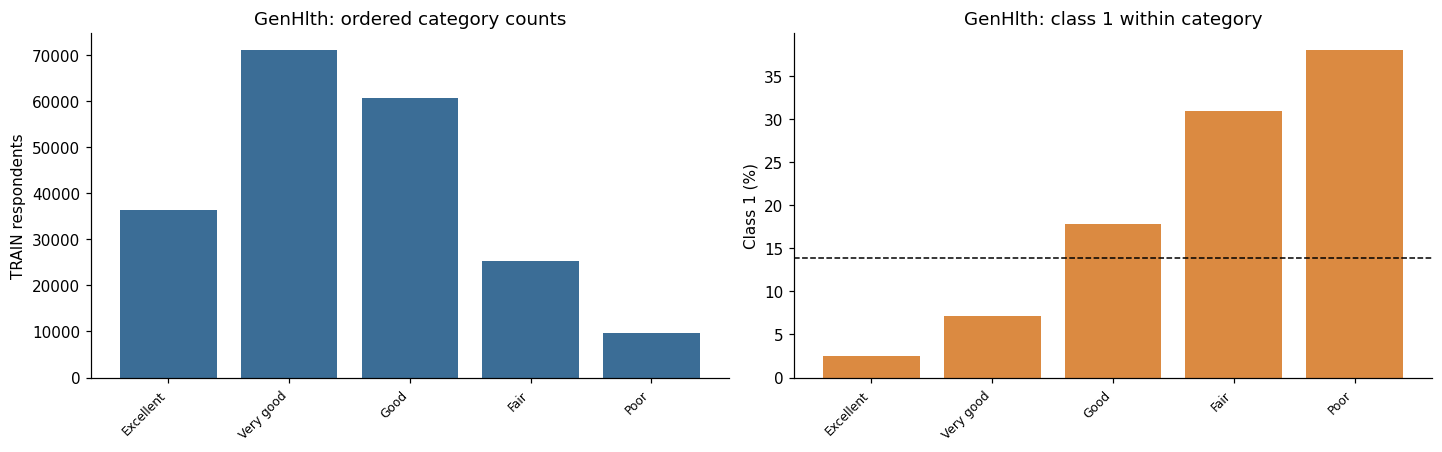

,Respondents,Class 1 count,Share of TRAIN (%),Class 1 (%)
18–24,4493,64,2.21,1.42
25–29,6073,111,2.99,1.83
30–34,8881,254,4.38,2.86
35–39,11048,471,5.44,4.26
40–44,12944,850,6.38,6.57
45–49,15932,1411,7.85,8.86
50–54,21108,2483,10.40,11.76
55–59,24777,3451,12.21,13.93
60–64,26537,4541,13.08,17.11
65–69,25679,5239,12.65,20.40


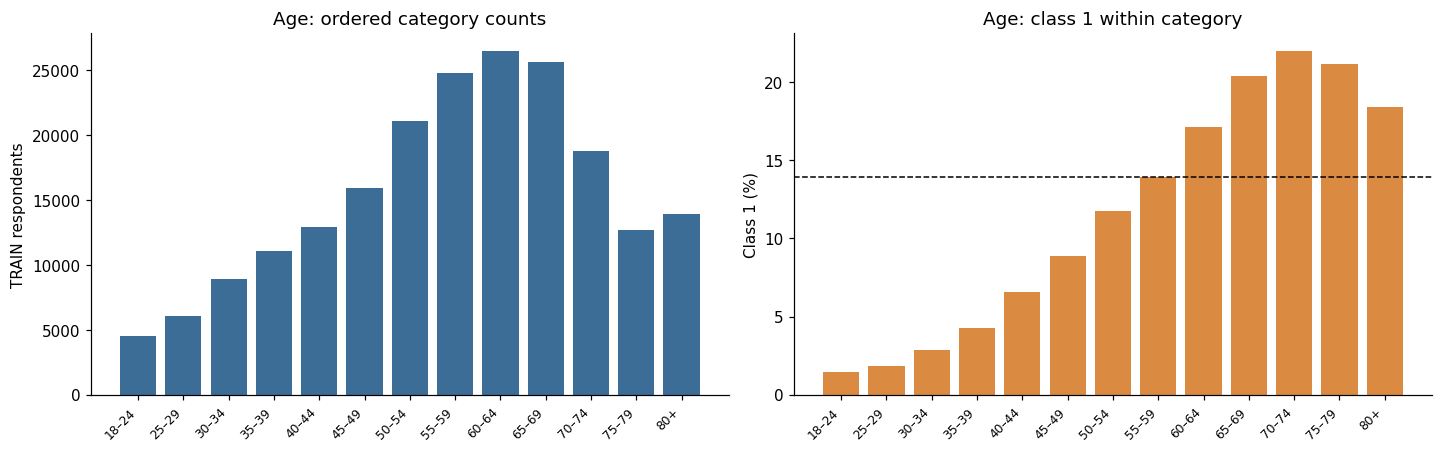

,Respondents,Class 1 count,Share of TRAIN (%),Class 1 (%)
No school / kindergarten,142,40,0.07,28.17
Grades 1–8,3248,962,1.60,29.62
Grades 9–11,7588,1830,3.74,24.12
High school graduate,50242,8825,24.76,17.56
Some college / technical,55862,8251,27.53,14.77
College / technical graduate,85862,8369,42.31,9.75


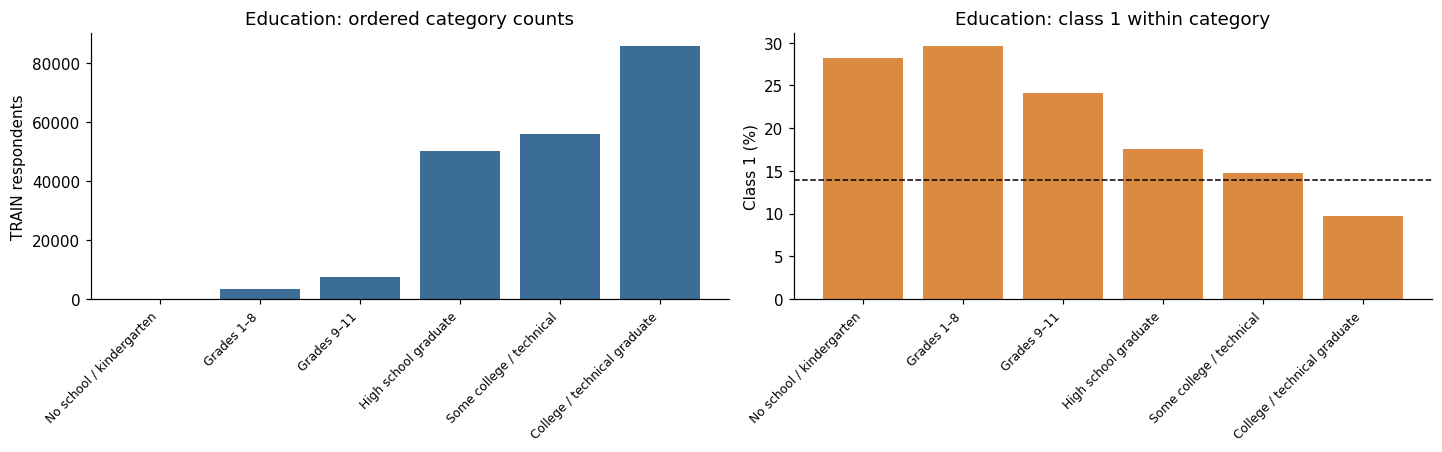

,Respondents,Class 1 count,Share of TRAIN (%),Class 1 (%)
<$10k,7870,1908,3.88,24.24
$10k–<15k,9458,2456,4.66,25.97
$15k–<20k,12832,2862,6.32,22.30
$20k–<25k,16145,3275,7.96,20.28
$25k–<35k,20709,3614,10.20,17.45
$35k–<50k,29189,4254,14.38,14.57
$50k–<75k,34489,4181,16.99,12.12
$75k+,72252,5727,35.60,7.93


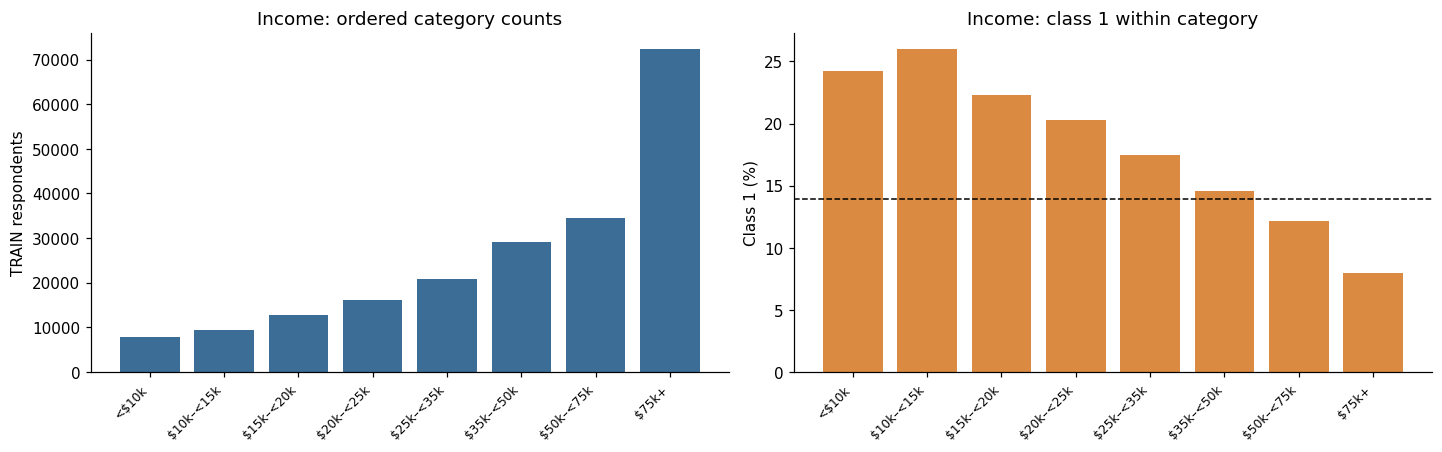

In [7]:
ordinal_tables = {col: category_summary(train_df, col) for col in ordinal_features}
for col, summary in ordinal_tables.items():
    labeled = summary.copy()
    labeled.index = ordinal_labels[col]
    print(col)
    display(labeled.round(2))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
    positions = np.arange(len(labeled))
    axes[0].bar(positions, labeled['Respondents'], color='#3B6D96')
    axes[1].bar(positions, labeled['Class 1 (%)'], color='#DB8A41')
    axes[1].axhline(100 * y_train.mean(), color='black', linestyle='--', linewidth=1)
    for ax in axes:
        ax.set_xticks(positions, labeled.index, rotation=45, ha='right', fontsize=8)
    axes[0].set(title=f'{col}: ordered category counts', ylabel='TRAIN respondents')
    axes[1].set(title=f'{col}: class 1 within category', ylabel='Class 1 (%)')
    plt.show()

assert set(numerical_features + list(binary_tables) + list(ordinal_tables)) == set(X.columns)
print('EDA coverage: all 21 input features explored.')

## 7. Five informative EDA findings (Q3)
The summaries below use TRAIN evidence. The observations describe associations in this survey sample; they do not establish causes or a feature's independent effect after adjusting for other predictors.

In [8]:
bmi_means = train_df.groupby(target)['BMI'].mean()
bp = binary_tables['HighBP']['Class 1 (%)']
general = ordinal_tables['GenHlth']['Class 1 (%)']
age_rates = ordinal_tables['Age']['Class 1 (%)']
alcohol = binary_tables['HvyAlcoholConsump']['Class 1 (%)']
findings = [
    ('Does BMI differ between classes?',
     f'Mean BMI is {bmi_means.loc[0]:.2f} in class 0 and {bmi_means.loc[1]:.2f} in class 1.',
     'Class 1 has a higher average BMI, but the distributions overlap. Retain BMI; it cannot separate the classes by itself.'),
    ('Is high blood pressure associated with the target?',
     f'Class 1 is {bp.loc[0]:.2f}% without high blood pressure and {bp.loc[1]:.2f}% with it.',
     'HighBP shows an association worth retaining. These rates do not establish a causal or independent effect.'),
    ('Does general health show an ordered pattern?',
     f'Class 1 is {general.loc[1]:.2f}% in excellent health and {general.loc[5]:.2f}% in poor health.',
     'Poorer self-rated health is associated with the target. Health may also be affected by existing illness, so direction cannot be inferred.'),
    ('Does class 1 increase uniformly with age?',
     f'Class 1 is {age_rates.loc[1]:.2f}% at ages 18–24; the highest rate is {age_rates.max():.2f}% '
     f'in group {ordinal_labels["Age"][int(age_rates.idxmax()) - 1]}; it is {age_rates.loc[13]:.2f}% at 80+.',
     'Age-group differences matter, but the pattern need not be linear or rise at every step. A single ordinal slope is a simplification.'),
    ('How should we read the alcohol association?',
     f'Class 1 is {alcohol.loc[0]:.2f}% for code 0 and {alcohol.loc[1]:.2f}% for code 1.',
     'A lower observed rate in the heavy-consumption category is not evidence of protection. Age, reporting and behaviour changes after illness may help explain it.')
]
for i, (question, evidence, decision) in enumerate(findings, 1):
    display(Markdown(f'### Finding {i}: {question}\n**Evidence:** {evidence}\n\n**Interpretation and decision:** {decision}'))

### Finding 1: Does BMI differ between classes?
**Evidence:** Mean BMI is 27.80 in class 0 and 31.97 in class 1.

**Interpretation and decision:** Class 1 has a higher average BMI, but the distributions overlap. Retain BMI; it cannot separate the classes by itself.

### Finding 2: Is high blood pressure associated with the target?
**Evidence:** Class 1 is 6.03% without high blood pressure and 24.46% with it.

**Interpretation and decision:** HighBP shows an association worth retaining. These rates do not establish a causal or independent effect.

### Finding 3: Does general health show an ordered pattern?
**Evidence:** Class 1 is 2.52% in excellent health and 38.06% in poor health.

**Interpretation and decision:** Poorer self-rated health is associated with the target. Health may also be affected by existing illness, so direction cannot be inferred.

### Finding 4: Does class 1 increase uniformly with age?
**Evidence:** Class 1 is 1.42% at ages 18–24; the highest rate is 22.03% in group 70–74; it is 18.38% at 80+.

**Interpretation and decision:** Age-group differences matter, but the pattern need not be linear or rise at every step. A single ordinal slope is a simplification.

### Finding 5: How should we read the alcohol association?
**Evidence:** Class 1 is 14.41% for code 0 and 5.81% for code 1.

**Interpretation and decision:** A lower observed rate in the heavy-consumption category is not evidence of protection. Age, reporting and behaviour changes after illness may help explain it.

**Overall feature decision:** retain all 21 predictors for this introductory model. A weak marginal association alone is not a sufficient reason to discard a feature, and these plots do not rank adjusted model importance. We do not tune feature selection against TEST.

## 8. Prepare features with one pipeline
**Question:** How should each feature type enter Logistic Regression?

| Type | Representation | Reason and limitation |
|---|---|---|
| BMI, MentHlth, PhysHlth | StandardScaler fitted on TRAIN | Gives comparable scales for regularized Logistic Regression; day counts remain numerical |
| Binary features | Pass through as 0/1 | Already encoded; no additional encoding is needed |
| Ordered features | Keep documented ordered codes and scale using TRAIN | Preserves order, but imposes a constant log-odds change per category step |

Ordinal codes are **ranks**, not measured age or income. Using one scaled rank per feature is a simple course-level choice, but scaling does not remove the equal-step modelling assumption. For example, the open-ended oldest age category is not an equal interval in years. A more flexible representation could be investigated later using validation within TRAIN; it is not selected using TEST here.

`ColumnTransformer` handles the three groups explicitly. The complete pipeline fits the scaler and Logistic Regression on TRAIN. Applying `.transform` or `.predict` to TEST reuses those learned values; it does not refit them. Learning scaling parameters from all rows would let TEST information enter model development.

In [9]:
preprocessor = ColumnTransformer([
    ('numerical', StandardScaler(), numerical_features),
    ('binary', 'passthrough', binary_features),
    ('ordinal', StandardScaler(), ordinal_features)
], remainder='drop')

model = Pipeline([
    ('preprocessing', preprocessor),
    ('logistic_regression', LogisticRegression(
        solver='lbfgs', C=1.0, max_iter=1000, random_state=RANDOM_STATE
    ))
])
model

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numerical', StandardScaler(),
                                                  ['BMI', 'MentHlth',
                                                   'PhysHlth']),
                                                 ('binary', 'passthrough',
                                                  ['HighBP', 'HighChol',
                                                   'CholCheck', 'Smoker',
                                                   'Stroke',
                                                   'HeartDiseaseorAttack',
                                                   'PhysActivity', 'Fruits',
                                                   'Veggies',
                                                   'HvyAlcoholConsump',
                                                   'AnyHealthcare',
                                                   'NoDocbcCost', 'DiffWalk',
                                   

## 9. Fit Logistic Regression on TRAIN
We fit one model using the original TRAIN class distribution and standard L2 regularization (`C=1.0`). No class balancing, hyperparameter search or TEST-based adjustment is performed. A larger iteration limit allows the optimizer to converge; it is not a performance target.

Logistic Regression estimates a class-1 probability from a linear combination of the prepared predictors. A probability becomes a class only after applying a threshold.

In [10]:
model.fit(X_train, y_train)
iterations = model.named_steps['logistic_regression'].n_iter_[0]
print('Training rows:', len(X_train))
print('Optimization iterations:', iterations)
assert iterations < model.named_steps['logistic_regression'].max_iter, 'Investigate convergence.'
print('Pipeline fitted using TRAIN only.')

Training rows: 202944
Optimization iterations: 38
Pipeline fitted using TRAIN only.


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numerical', StandardScaler(),
                                                  ['BMI', 'MentHlth',
                                                   'PhysHlth']),
                                                 ('binary', 'passthrough',
                                                  ['HighBP', 'HighChol',
                                                   'CholCheck', 'Smoker',
                                                   'Stroke',
                                                   'HeartDiseaseorAttack',
                                                   'PhysActivity', 'Fruits',
                                                   'Veggies',
                                                   'HvyAlcoholConsump',
                                                   'AnyHealthcare',
                                                   'NoDocbcCost', 'DiffWalk',
                                   

## 10. Final TEST evaluation (Q5)
The features, preprocessing and model settings are now fixed. We evaluate on the untouched TEST distribution. `predict` returns classes; `predict_proba` returns class probabilities. Column 1 is the probability of class 1, which we verify from the fitted class labels.

In each confusion matrix, **rows are actual classes and columns are predicted classes**:

| | Predicted 0 | Predicted 1 |
|---|---|---|
| Actual 0 | True negative (TN) | False positive (FP) |
| Actual 1 | False negative (FN) | True positive (TP) |

A false positive is a respondent with target 0 predicted as prediabetes/diabetes. A false negative is a respondent with target 1 predicted as no diabetes.

,Accuracy,Precision,Recall,F1,True negatives,False positives,False negatives,True positives
Always predict 0,0.8607,0.0000,0.0000,0.0000,43667.0,0.0,7069.0,0.0
Logistic Regression (predict),0.8621,0.5164,0.1579,0.2418,42622.0,1045.0,5953.0,1116.0


Text(0.5, 1.0, 'Logistic Regression: TEST confusion matrix')

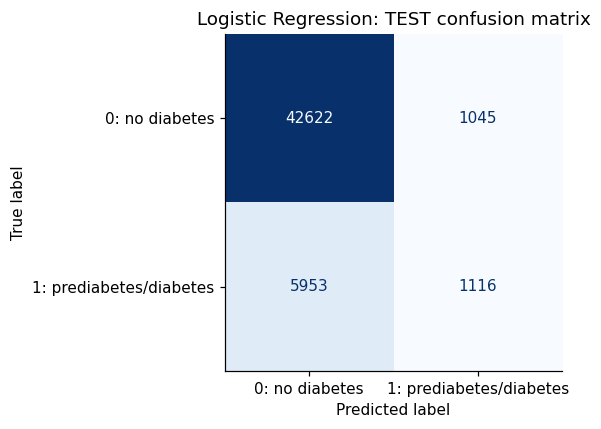

In [11]:
assert np.array_equal(model.classes_, [0, 1])
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

def evaluate_predictions(actual, predicted):
    tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
    return {'Accuracy': accuracy_score(actual, predicted),
            'Precision': precision_score(actual, predicted, zero_division=0),
            'Recall': recall_score(actual, predicted, zero_division=0),
            'F1': f1_score(actual, predicted, zero_division=0),
            'True negatives': int(tn), 'False positives': int(fp),
            'False negatives': int(fn), 'True positives': int(tp)}

baseline_pred = np.zeros_like(y_test)
model_results = evaluate_predictions(y_test, y_pred)
evaluation_table = pd.DataFrame({
    'Always predict 0': evaluate_predictions(y_test, baseline_pred),
    'Logistic Regression (predict)': model_results
}).T
display(evaluation_table.round(4))
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=[0, 1],
    display_labels=['0: no diabetes', '1: prediabetes/diabetes'],
    cmap='Blues', colorbar=False, values_format='d', ax=ax)
ax.set_title('Logistic Regression: TEST confusion matrix')
plt.tight_layout()
plt.show()

In [12]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
display(Markdown(
    f'**Reading our results:** the model correctly identifies **{tp:,}** class-1 respondents and misses '
    f'**{fn:,}** (false negatives). It labels **{fp:,}** class-0 respondents as class 1 (false positives), '
    f'while **{tn:,}** are correctly classified as class 0.\n\n'
    f'- **Accuracy = (TP + TN) / N = {model_results["Accuracy"]:.2%}:** fraction correct overall.\n'
    f'- **Precision = TP / (TP + FP) = {model_results["Precision"]:.2%}:** of predicted class 1, the fraction actually class 1.\n'
    f'- **Recall = TP / (TP + FN) = {model_results["Recall"]:.2%}:** of actual class 1, the fraction detected.\n'
    f'- **F1 = 2 × precision × recall / (precision + recall) = {model_results["F1"]:.4f}:** '
    f'harmonic mean of precision and recall; it does not account for true negatives.\n\n'
    'The always-0 baseline has zero recall. Its precision is undefined because it predicts no positives; '
    'we report zero using `zero_division=0`. Comparing it with our model shows why high accuracy alone is insufficient. '
    'False negatives mean missed class-1 cases; false positives could lead to unnecessary follow-up in a hypothetical screening setting. '
    'This assignment does not establish clinical suitability.'
))

**Reading our results:** the model correctly identifies **1,116** class-1 respondents and misses **5,953** (false negatives). It labels **1,045** class-0 respondents as class 1 (false positives), while **42,622** are correctly classified as class 0.

- **Accuracy = (TP + TN) / N = 86.21%:** fraction correct overall.
- **Precision = TP / (TP + FP) = 51.64%:** of predicted class 1, the fraction actually class 1.
- **Recall = TP / (TP + FN) = 15.79%:** of actual class 1, the fraction detected.
- **F1 = 2 × precision × recall / (precision + recall) = 0.2418:** harmonic mean of precision and recall; it does not account for true negatives.

The always-0 baseline has zero recall. Its precision is undefined because it predicts no positives; we report zero using `zero_division=0`. Comparing it with our model shows why high accuracy alone is insufficient. False negatives mean missed class-1 cases; false positives could lead to unnecessary follow-up in a hypothetical screening setting. This assignment does not establish clinical suitability.

## 11. Compare probability thresholds 0.50 and 0.40 (Q6)
**Question:** What changes when we lower the cutoff while keeping the fitted model fixed?

For this comparison, predict class 1 when `probability >= threshold`. The two thresholds are specified by the assignment, not optimized on TEST. We compute all requested metrics and both confusion matrices from the **same probabilities**. An exact probability of 0.50 can be handled differently by `predict`; we check whether that makes any difference in this dataset.

Differences between predict() and the >= 0.50 rule: 0


,Accuracy,Precision,Recall,F1,False positives,False negatives
Threshold,,,,,,
0.5,0.8621,0.5164,0.1579,0.2418,1045,5953
0.4,0.8562,0.4716,0.2686,0.3423,2128,5170


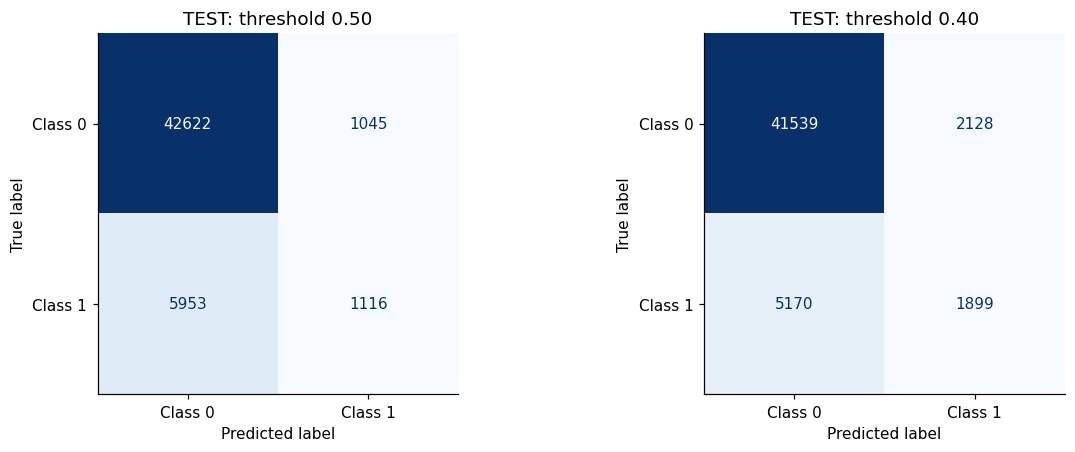

[Text(0.5, 0, 'Predicted probability of class 1'), Text(0, 0.5, 'Density'), Text(0.5, 1.0, 'Same TEST probabilities; two decision thresholds')]

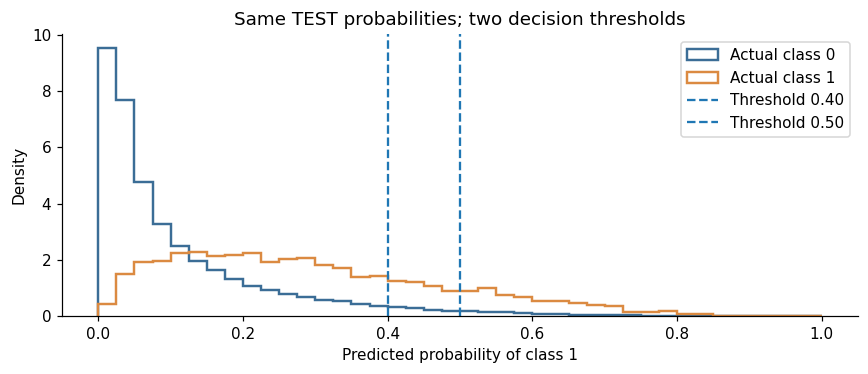

In [13]:
threshold_predictions = {}
threshold_rows = []
for threshold in [0.50, 0.40]:
    predictions = (y_proba >= threshold).astype(int)
    threshold_predictions[threshold] = predictions
    row = {'Threshold': threshold, **evaluate_predictions(y_test, predictions)}
    threshold_rows.append(row)
threshold_results = pd.DataFrame(threshold_rows).set_index('Threshold')
required_columns = ['Accuracy', 'Precision', 'Recall', 'F1', 'False positives', 'False negatives']
display(threshold_results[required_columns].round(4))
print('Differences between predict() and the >= 0.50 rule:',
      np.count_nonzero(y_pred != threshold_predictions[0.50]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, threshold in zip(axes, [0.50, 0.40]):
    ConfusionMatrixDisplay.from_predictions(y_test, threshold_predictions[threshold],
        labels=[0, 1], display_labels=['Class 0', 'Class 1'], cmap='Blues',
        colorbar=False, values_format='d', ax=ax)
    ax.set_title(f'TEST: threshold {threshold:.2f}')
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.5))
for cls, color in [(0, '#3B6D96'), (1, '#DB8A41')]:
    ax.hist(y_proba[y_test.to_numpy() == cls], bins=np.linspace(0, 1, 41),
            density=True, histtype='step', linewidth=1.6, color=color, label=f'Actual class {cls}')
for threshold in [0.40, 0.50]:
    ax.axvline(threshold, linestyle='--', label=f'Threshold {threshold:.2f}')
ax.set(xlabel='Predicted probability of class 1', ylabel='Density',
       title='Same TEST probabilities; two decision thresholds')
ax.legend()
plt.tight_layout()
plt.show()

In [14]:
r50, r40 = threshold_results.loc[0.50], threshold_results.loc[0.40]
switched = int(np.sum(threshold_predictions[0.50] != threshold_predictions[0.40]))
display(Markdown(
    f'Lowering the threshold changes **{switched:,}** predictions from class 0 to class 1. '
    f'These respondents have predicted probabilities in [0.40, 0.50).\n\n'
    f'- False positives: **{int(r50["False positives"]):,} → {int(r40["False positives"]):,}**.\n'
    f'- False negatives: **{int(r50["False negatives"]):,} → {int(r40["False negatives"]):,}**.\n'
    f'- Precision: **{r50["Precision"]:.2%} → {r40["Precision"]:.2%}**.\n'
    f'- Recall: **{r50["Recall"]:.2%} → {r40["Recall"]:.2%}**.\n'
    f'- Accuracy: **{r50["Accuracy"]:.2%} → {r40["Accuracy"]:.2%}**; '
    f'F1: **{r50["F1"]:.4f} → {r40["F1"]:.4f}**.\n\n'
    '**What did not change:** the TRAIN/TEST split, preprocessing parameters, model coefficients, '
    'predicted probabilities, probability ranking and true target labels. No retraining occurred.\n\n'
    '**Interpretation:** the lower threshold catches more class-1 respondents but also flags more class-0 respondents. '
    'For fixed probabilities, lowering a threshold cannot reduce recall or increase false negatives; '
    'precision is not guaranteed to change monotonically in every dataset. Here, the table gives the observed trade-off. '
    'A preferred operating threshold would require an explicit cost or purpose and validation within TRAIN, '
    'rather than choosing the best-looking TEST result.'
))

Lowering the threshold changes **1,866** predictions from class 0 to class 1. These respondents have predicted probabilities in [0.40, 0.50).

- False positives: **1,045 → 2,128**.
- False negatives: **5,953 → 5,170**.
- Precision: **51.64% → 47.16%**.
- Recall: **15.79% → 26.86%**.
- Accuracy: **86.21% → 85.62%**; F1: **0.2418 → 0.3423**.

**What did not change:** the TRAIN/TEST split, preprocessing parameters, model coefficients, predicted probabilities, probability ranking and true target labels. No retraining occurred.

**Interpretation:** the lower threshold catches more class-1 respondents but also flags more class-0 respondents. For fixed probabilities, lowering a threshold cannot reduce recall or increase false negatives; precision is not guaranteed to change monotonically in every dataset. Here, the table gives the observed trade-off. A preferred operating threshold would require an explicit cost or purpose and validation within TRAIN, rather than choosing the best-looking TEST result.

## 12. Conclusion and limitations (Q7)
Our EDA covers all 21 predictors and shows that feature meaning matters as much as storage type. BMI, high blood pressure and poorer general health show useful class differences. The age pattern is not uniformly linear, and an apparently favourable alcohol association cannot be interpreted as a protective effect.

Logistic Regression provides a reproducible baseline, but the confusion matrices show that accuracy does not summarize its ability to find class 1. At 0.50 it misses many class-1 respondents. Lowering the threshold to 0.40 improves detection at the cost of more false positives, using exactly the same fitted probabilities. Neither threshold is automatically the best choice for an unspecified real-world use.

**Limitations:**

1. **Observational survey data:** self-reporting, selection and unmeasured confounding can affect associations. The analysis does not show that a feature causes diabetes or establish the time direction of an association.
2. **Combined target:** class 1 combines prediabetes and diabetes, so the model cannot distinguish them. It classifies recorded status rather than demonstrating prediction of future disease.
3. **Simple model representation:** Logistic Regression assumes an additive linear relationship with log-odds. Ordered codes impose a constant effect per category step; the age EDA suggests this can be restrictive. We have not modelled nonlinearities or interactions.
4. **Evaluation scope:** one random split gives one estimate of performance. We have not measured variation across splits, external validity, subgroup performance or probability calibration. A held-out sample from the same dataset does not establish usefulness in another population.
5. **Class imbalance and operating costs:** the minority class can be missed despite high accuracy. The assignment's threshold comparison does not specify the relative consequences of false positives and false negatives.

We preserved TEST, retained all supplied respondents, and fitted every learned preprocessing step on TRAIN. The notebook supports explanation and discussion; no minimum accuracy target or claim of clinical readiness is made.

## Where to find evidence for the written questions

| Question | Notebook evidence |
|---|---|
| Q1: target meaning and imbalance | Section 1: class table and baseline interpretation |
| Q2: three feature types | Section 2: meaning table and feature groups |
| Q3: informative EDA findings | Sections 4–7: distributions, category tables and five findings |
| Q4: protect TEST | Sections 3 and 8: split and fitted preprocessing |
| Q5: errors and metrics | Section 10: confusion matrix, baseline and definitions |
| Q6: threshold comparison | Section 11: required table, matrices and interpretation |
| Q7: conclusion and limitations | Section 12 |

Group contributions and how everyone learned the full workflow should be described from the group's actual experience in the separate G1–G2 reflection.